# Linear regression

## Univariate linear regression

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['SimHei'] #It is used to display Chinese labels properly
plt.rcParams['axes.unicode_minus']=False #Used to display the minus sign normally

In [5]:
path = 'data/regress_data1.csv'
data = pd.read_csv(path)
data.head()

,人口,收益
0,6.1101,17.5920
1,5.5277,9.1302
2,8.5186,13.6620
3,7.0032,11.8540
4,5.8598,6.8233


In [6]:
data.describe()

,人口,收益
count,97.000000,97.000000
mean,8.159800,5.839135
std,3.869884,5.510262
min,5.026900,-2.680700
25%,5.707700,1.986900
50%,6.589400,4.562300
75%,8.578100,7.046700
max,22.203000,24.147000


What does the data look like

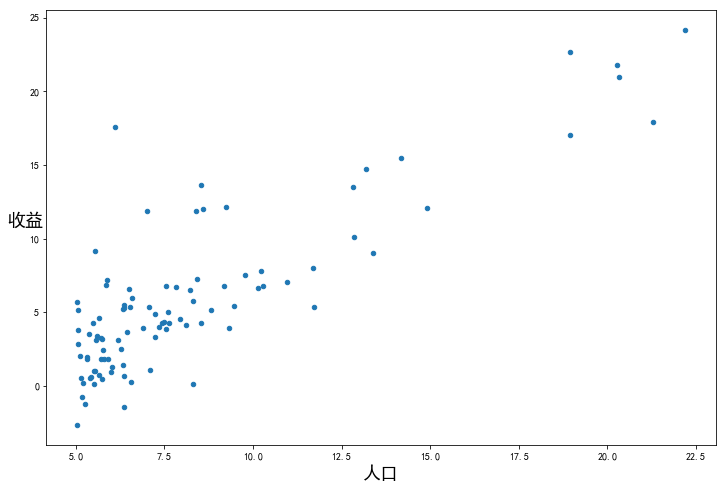

In [7]:
data.plot(kind='scatter', x='人口', y='收益', figsize=(12,8))
plt.xlabel('人口', fontsize=18)
plt.ylabel('收益', rotation=0, fontsize=18)
plt.show()

Now let's use gradient descent to implement linear regression to minimize the cost function.

First, we will create a cost function with the parameter $w$ as the characteristic function

𝐽(𝑤)=12𝑚∑𝑖=1𝑚(ℎ(𝑥(𝑖))−𝑦(𝑖))2
 
其中：
ℎ(𝑥)=𝑤𝑇𝑋=𝑤0𝑥0+𝑤1𝑥1+𝑤2𝑥2+...+𝑤𝑛𝑥𝑛

In [8]:
def computeCost(X, y, w):
    inner = np.power(((X * w.T) - y), 2)# (m,n) @ (n, 1) -> (n, 1)
#     return np.sum(inner) / (2 * len(X))
    return np.sum(inner) / (2 * X.shape[0])

Let's add a column to the training set so that we can use vectorization solutions to calculate costs and gradients.

In [9]:
data.insert(0, 'Ones', 1)
data

,Ones,人口,收益
0,1,6.1101,17.59200
1,1,5.5277,9.13020
2,1,8.5186,13.66200
3,1,7.0032,11.85400
4,1,5.8598,6.82330
5,1,8.3829,11.88600
6,1,7.4764,4.34830
7,1,8.5781,12.00000
8,1,6.4862,6.59870
9,1,5.0546,3.81660


In [ ]:
Now let's do some variable initialization.

In [10]:
# set X (training data) and y (target variable)
cols = data.shape[1]
X = data.iloc[:,:cols-1]#X is all the rows, minus the last column
y = data.iloc[:,cols-1:]#Y is all the rows, the last column

In [ ]:
See if X (training set) and y (target variable) are correct.

In [11]:
X.head()#head()是观察前5行

,Ones,人口
0,1,6.1101
1,1,5.5277
2,1,8.5186
3,1,7.0032
4,1,5.8598


In [12]:
y.head()

,收益
0,17.5920
1,9.1302
2,13.6620
3,11.8540
4,6.8233


In [ ]:
The cost function is supposed to be a numpy matrix, so we need to convert X and Y before we can use them. We also need to initialize w.

In [13]:
X = np.matrix(X.values)
y = np.matrix(y.values)
w = np.matrix(np.array([0,0]))

In [ ]:
w is a (1,2) matrix

In [14]:
w

matrix([[0, 0]])

In [ ]:
Let's look at the dimensions

In [15]:
X.shape, w.shape, y.shape

((97, 2), (1, 2), (97, 1))

In [ ]:
Compute the cost function (theta starts at 0).

In [16]:
computeCost(X, y, w)

32.072733877455676

# Batch Gradient Decent（批量梯度下降）

$${{w }_{j}}:={{w }_{j}}- \alpha \frac{1}{m}\sum\limits_{i=1}^m \frac{\partial }{\partial {{w}_{j}}}J\left( w \right)$$

In [17]:
def batch_gradientDescent(X, y, w, alpha, iters):
    temp = np.matrix(np.zeros(w.shape))
    parameters = int(w.ravel().shape[1])
    cost = np.zeros(iters)

    for i in range(iters):
        error = (X * w.T) - y

        for j in range(parameters):
            term = np.multiply(error, X[:, j])
            temp[0, j] = w[0, j] - ((alpha / len(X)) * np.sum(term))

        w = temp
        cost[i] = computeCost(X, y, w)

    return w, cost

In [ ]:
Initializes some additional variables - the learning rate α and the number of iterations to perform.

In [18]:
alpha = 0.01
iters = 1500

In [ ]:
Now let's run the gradient descent algorithm to fit our parameter θ to the training set.

In [19]:
g, cost = batch_gradientDescent(X, y, w, alpha, iters)
g

matrix([[-3.63029144,  1.16636235]])

In [ ]:
Finally, we can calculate the cost function (error) of the training model using the parameters we fit.

In [20]:
computeCost(X, y, g)

4.483388256587726

In [ ]:
Now let's plot the linear model and the data to see how it fits visually.

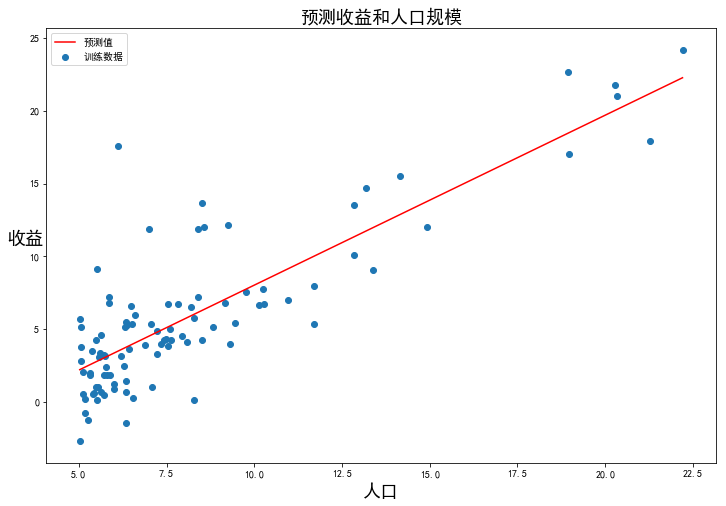

In [21]:
x = np.linspace(data['人口'].min(), data['人口'].max(), 100)
f = g[0, 0] + (g[0, 1] * x)

fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(x, f, 'r', label='预测值')
ax.scatter(data['人口'], data['收益'], label='训练数据')
ax.legend(loc=2)
ax.set_xlabel('人口', fontsize=18)
ax.set_ylabel('收益', rotation=0, fontsize=18)
ax.set_title('预测收益和人口规模', fontsize=18)
plt.show()

In [ ]:
Since the gradient equation function also outputs a cost vector in each training iteration, we can also plot. Note that the cost is always reduced - this is an example of a convex optimization problem.

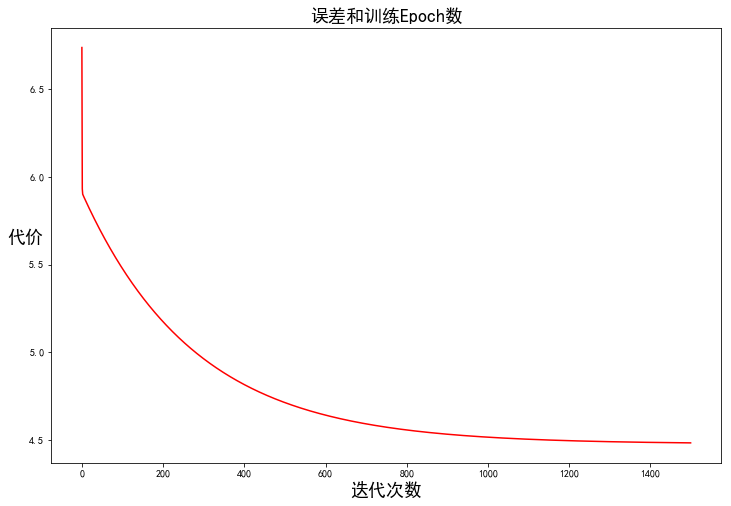

In [22]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(np.arange(iters), cost, 'r')
ax.set_xlabel('迭代次数', fontsize=18)
ax.set_ylabel('代价', rotation=0, fontsize=18)
ax.set_title('误差和训练Epoch数', fontsize=18)
plt.show()

In [ ]:
## multiple linear regression

In [ ]:
The exercise also includes a house price dataset with 2 variables (the size of the house, the number of bedrooms) and a goal (the price of the house). We analyze the data set using techniques we've already applied.

In [23]:
path = 'data/regress_data2.csv'
data2 = pd.read_csv(path)
data2.head()

,面积,房间数,价格
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


In [ ]:
For this task, we add another preprocessing step - feature normalization. This is easy for pandas

In [24]:
data2 = (data2 - data2.mean()) / data2.std()
data2.head()

,面积,房间数,价格
0,0.130010,-0.223675,0.475747
1,-0.504190,-0.223675,-0.084074
2,0.502476,-0.223675,0.228626
3,-0.735723,-1.537767,-0.867025
4,1.257476,1.090417,1.595389


In [ ]:
Now we repeat the preprocessing steps from Part 1 and run the linear regression program on the new data set.

In [25]:
# add ones column
data2.insert(0, 'Ones', 1)

# set X (training data) and y (target variable)
cols = data2.shape[1]
X2 = data2.iloc[:,0:cols-1]
y2 = data2.iloc[:,cols-1:cols]

# convert to matrices and initialize theta
X2 = np.matrix(X2.values)
y2 = np.matrix(y2.values)
w2 = np.matrix(np.array([0,0,0]))

# perform linear regression on the data set
g2, cost2 = batch_gradientDescent(X2, y2, w2, alpha, iters)

# get the cost (error) of the model
computeCost(X2, y2, g2)

0.13068670606095903

In [ ]:
We can also quickly view the training progress of this one.

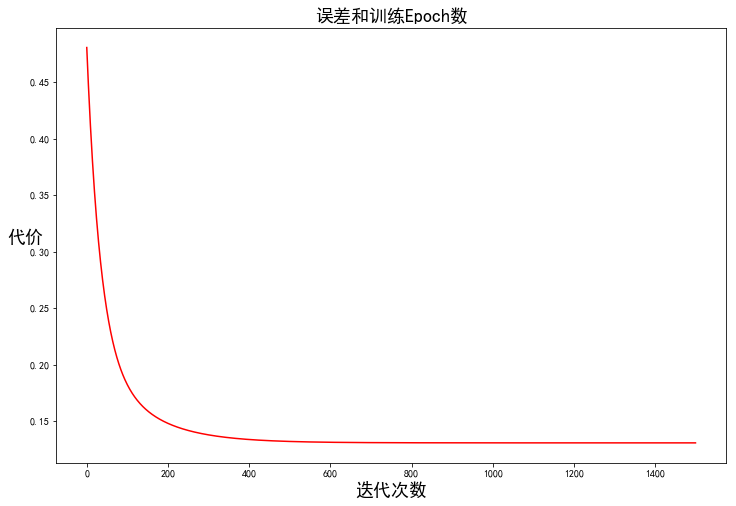

In [26]:
fig, ax = plt.subplots(figsize=(12,8))
ax.plot(np.arange(iters), cost2, 'r')
ax.set_xlabel('迭代次数', fontsize=18)
ax.set_ylabel('代价', rotation=0, fontsize=18)
ax.set_title('误差和训练Epoch数', fontsize=18)
plt.show()

In [ ]:
We can also use scikit-learn's linear regression function instead of implementing these algorithms from scratch. We apply scikit-learn's linear regression algorithm to the data from Part 1 and see how it performs.

In [28]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X, y)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=1, normalize=False)

In [ ]:
Predictive performance of the scikit-learn model

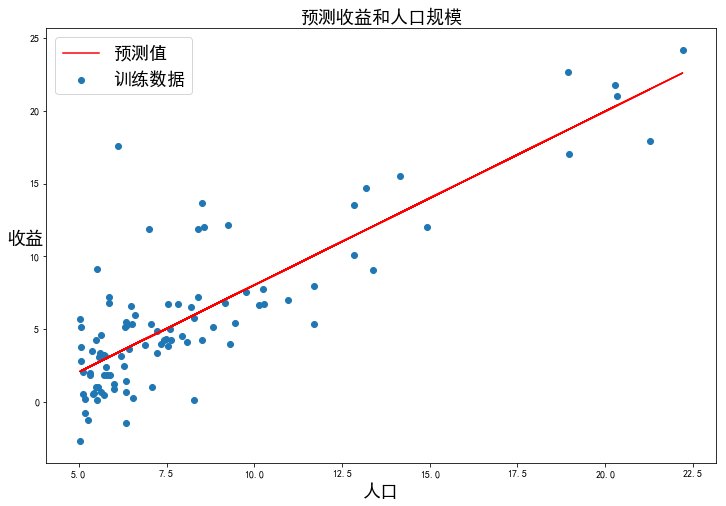

In [29]:
x = np.array(X[:, 1].A1)
f = model.predict(X).flatten()

fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(x, f, 'r', label='预测值')
ax.scatter(data['人口'], data['收益'], label='训练数据')
ax.legend(loc=2, fontsize=18)
ax.set_xlabel('人口', fontsize=18)
ax.set_ylabel('收益', rotation=0, fontsize=18)
ax.set_title('预测收益和人口规模', fontsize=18)
plt.show()

## $L_2$regularization
$J (  { w } ) = \frac { 1 } { 2 } \sum _ { i = 1 } ^ { m } ( h _ { w} ( x ^ { ( i ) } ) - y ^ { ( i ) } ) ^ { 2 } + \lambda \sum _ { j = 1 } ^ { n } w_ { j } ^ { 2 }$，此时称作`Ridge Regression`：

In [30]:
from sklearn.linear_model import Ridge
model = Ridge()
model.fit(X, y)

Ridge(alpha=1.0, copy_X=True, fit_intercept=True, max_iter=None,
   normalize=False, random_state=None, solver='auto', tol=0.001)

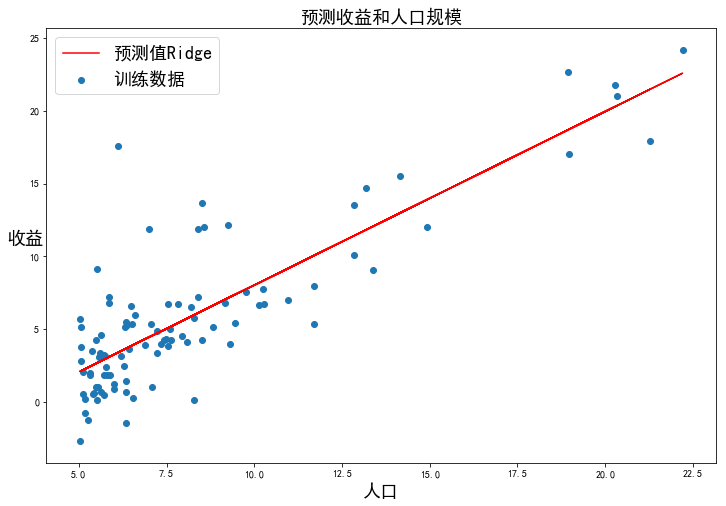

In [31]:
x2 = np.array(X[:, 1].A1)
f2 = model.predict(X).flatten()

fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(x2, f2, 'r', label='预测值Ridge')
ax.scatter(data['人口'], data['收益'], label='训练数据')
ax.legend(loc=2, fontsize=18)
ax.set_xlabel('人口', fontsize=18)
ax.set_ylabel('收益', rotation=0, fontsize=18)
ax.set_title('预测收益和人口规模', fontsize=18)
plt.show()

## adjust parameter

In [34]:
from sklearn.model_selection import cross_val_score
alphas = np.logspace(-3, 2, 50)
test_scores = []
for alpha in alphas:
    clf = Ridge(alpha)
    test_score = np.sqrt(-cross_val_score(clf, X, y, cv=5, scoring='neg_mean_squared_error'))
    test_scores.append(np.mean(test_score))

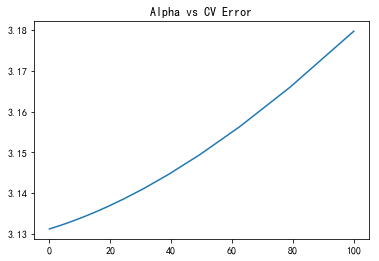

In [35]:
import matplotlib.pyplot as plt
plt.plot(alphas, test_scores)
plt.title("Alpha vs CV Error");
plt.show()

## (LSM)：

最小二乘法的需要求解最优参数$w^{*}$：

已知：目标函数

$J\left( w  \right)=\frac{1}{2m}\sum\limits_{i=1}^{m}{{{\left( {h}\left( {x^{(i)}} \right)-{y^{(i)}} \right)}^{2}}}$

其中：${h}\left( x \right)={w^{T}}X={w_{0}}{x_{0}}+{w_{1}}{x_{1}}+{w_{2}}{x_{2}}+...+{w_{n}}{x_{n}}$

将向量表达形式转为矩阵表达形式，则有$J(w )=\frac{1}{2}{{\left( Xw -y\right)}^{2}}$ ，其中$X$为$m$行$n+1$列的矩阵（$m$为样本个数，$n$为特征个数），$w$为$n+1$行1列的矩阵(包含了$w_0$)，$y$为$m$行1列的矩阵，则可以求得最优参数$w^{*} ={{\left( {X^{T}}X \right)}^{-1}}{X^{T}}y$ 


In [34]:
def LSM(X, y):
    w = np.linalg.inv(X.T@X)@X.T@y#X.T@X等价于X.T.dot(X)
    return w

In [35]:
final_w2=LSM(X, y)#感觉和批量梯度下降的theta的值有点差距
final_w2

matrix([[-3.89578088],
        [ 1.19303364]])

In [36]:
#梯度下降得到的结果是matrix([[-3.24140214,  1.1272942 ]])